In [1]:
import stim
from pymatching import Matching
import sinter
from typing import List
import matplotlib.pyplot as plt

In [8]:
distance = 5

surface_code_circuit = stim.Circuit.generated(
    "surface_code:unrotated_memory_z",
    rounds=9,
    distance=3,
    before_round_data_depolarization=0.04,
    before_measure_flip_probability=0.01)



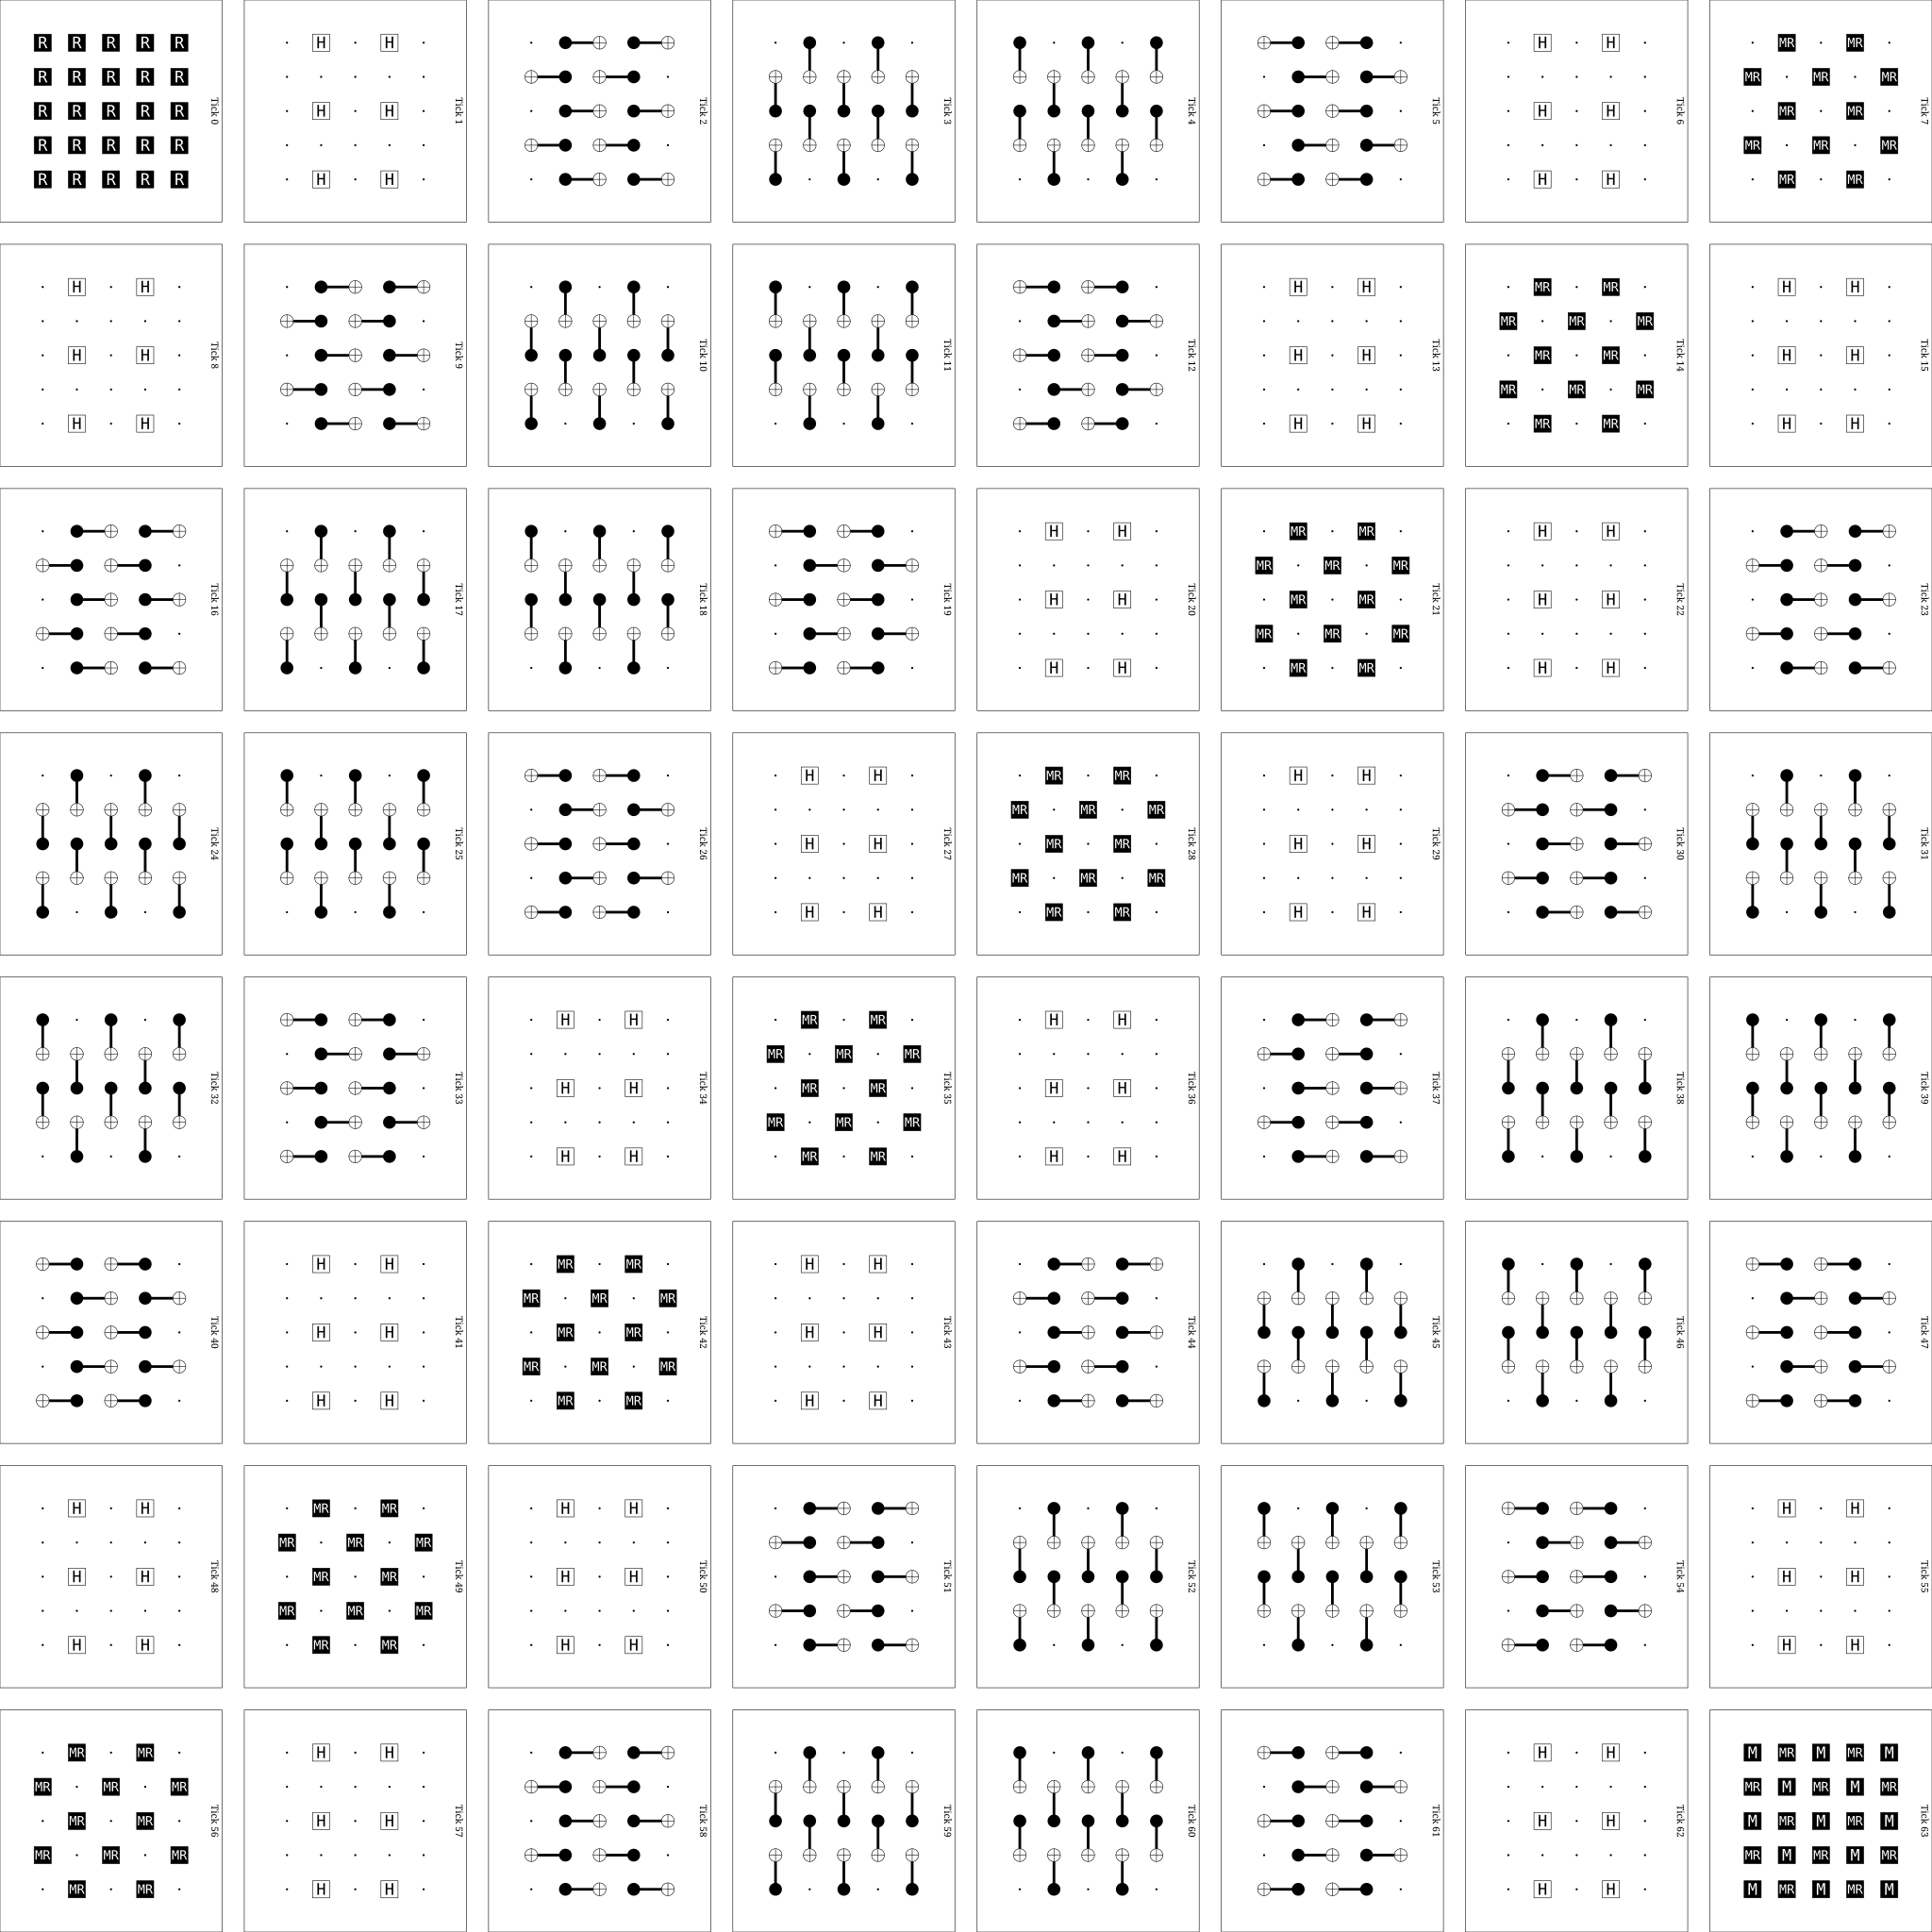

In [9]:
surface_code_circuit.without_noise().diagram("timeslice-svg")

In [8]:
import os

# X or Y noise
surface_code_tasks = [
    sinter.Task(
        circuit = stim.Circuit.generated(
            "surface_code:unrotated_memory_z",
            rounds=d,
            distance=d,
            before_measure_flip_probability=2*noise/3,
            before_round_data_depolarization=noise,
        ),
        json_metadata={'d': d, 'r': d, 'p': noise},
    )
    for d in [3, 5, 7, 9, 11]
    for noise in [0.036, 0.039, 0.042, 0.045, 0.048, 0.051] 
]

collected_surface_code_stats: List[sinter.TaskStats] = sinter.collect(
    num_workers=os.cpu_count(),
    tasks=surface_code_tasks,
    decoders=['pymatching'],
    max_shots=5_000_000,
    max_errors=100_000,
    print_progress=True,
)



Starting 20 workers...
30 tasks left:
  workers    decoder eta shots_left errors_left json_metadata    
        1 pymatching   ?    5000000      100000 d=3,r=3,p=0.036  
        1 pymatching   ?    5000000      100000 d=3,r=3,p=0.039  
        1 pymatching   ?    5000000      100000 d=3,r=3,p=0.042  
        1 pymatching <1m    4993583       99261 d=3,r=3,p=0.045  
        1 pymatching   ?    5000000      100000 d=3,r=3,p=0.048  
        1 pymatching   ?    5000000      100000 d=3,r=3,p=0.051  
        1 pymatching   ?    5000000      100000 d=5,r=5,p=0.036  
        1 pymatching   ?    5000000      100000 d=5,r=5,p=0.039  
        1 pymatching   ?    5000000      100000 d=5,r=5,p=0.042  
        1 pymatching   ?    5000000      100000 d=5,r=5,p=0.045  
        1 pymatching   ?    5000000      100000 d=5,r=5,p=0.048  
        1 pymatching   ?    5000000      100000 d=5,r=5,p=0.051  
        1 pymatching   ?    5000000      100000 d=7,r=7,p=0.036  
        1 pymatching   ?    5000000   

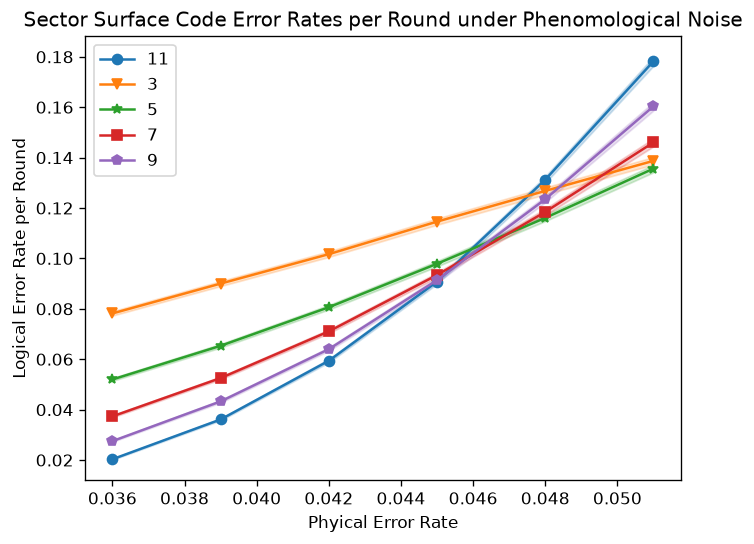

In [13]:

fig, ax = plt.subplots(1, 1)
sinter.plot_error_rate(
    ax=ax,
    stats=collected_surface_code_stats,
    x_func=lambda stat: stat.json_metadata['p'],
    group_func=lambda stat: stat.json_metadata['d'],
    # failure_units_per_shot_func=lambda stat: stat.json_metadata['r'],
)
# ax.set_ylim(5e-2, 1.5e-1)
# ax.set_xlim(0.04, 0.05)
ax.loglog()
ax.set_title("Sector Surface Code Error Rates per Round under Phenomological Noise")
ax.set_xlabel("Phyical Error Rate")
ax.set_ylabel("Logical Error Rate per Round")
# ax.grid(which='major')
# ax.grid(which='minor')
ax.set_xscale('linear')   # log-x hides a crossing on a narrow grid
ax.set_yscale('linear')
ax.legend()
fig.set_dpi(120)
plt.savefig('../../figs/stim_surface_d_depol_logic_error.png')

In [27]:
print(collected_surface_code_stats)

[sinter.TaskStats(strong_id='bcf3247913707259b119e233df58a6d895840358276270a3636d181892ccf4bd', decoder='pymatching', json_metadata={'d': 3, 'r': 9, 'p': 0.035}, shots=65809, errors=5000, seconds=0.08044349399278872), sinter.TaskStats(strong_id='6e8d0693e66dba2128c2687d0dd4d5bfc0c82b21177e6004ef8cf50a25fbe27e', decoder='pymatching', json_metadata={'d': 3, 'r': 9, 'p': 0.075}, shots=21777, errors=5140, seconds=0.050583591997565236), sinter.TaskStats(strong_id='41b0f1dffde5e58a706d8f8370c26cd8c724c63418ba296ee531b46fcaf56390', decoder='pymatching', json_metadata={'d': 3, 'r': 9, 'p': 0.02}, shots=181521, errors=5017, seconds=0.1358008659153711), sinter.TaskStats(strong_id='a84ebb7119640e7ef91d523ddbb3ef87b68cf0b2db5fd7916cf8dbb8a0d47ffe', decoder='pymatching', json_metadata={'d': 3, 'r': 9, 'p': 0.05}, shots=37137, errors=5076, seconds=0.07013677097711479), sinter.TaskStats(strong_id='0e35a8817c6cd272b65be54204819d92a439d8449184d046783a5531fc079a08', decoder='pymatching', json_metadata={

In [14]:
1 - (1-0.045)**2

0.08797500000000003